# 05 · Weekly factor model and walk-forward test

Factors: oil, gas, a crack-spread **proxy** (change in the Brent-WTI spread, because gasoline and heating-oil futures are not in the snapshot), the change in the 10-year yield and Fama-French 3. No dollar series exists in the snapshot, so none is used. Full-sample fits use HAC errors. Out-of-sample R² comes from an expanding window refit every week with no look-ahead.

In [1]:
import sys, json
sys.path.insert(0, "..")
import pandas as pd
pd.set_option("display.float_format", "{:,.3f}".format)
from IPython.display import Image, Markdown, display

In [2]:
from src.analysis import factor_model as fm
res = fm.compute()
res['sample'], res['crack_spread_proxy'], res['dollar_proxy']

({'first_week': Timestamp('2015-01-09 00:00:00'),
  'last_week': Timestamp('2026-08-28 00:00:00'),
  'n_weeks': 608},
 'weekly change in (Brent - WTI) / WTI from BZ=F and CL=F futures; RBOB/heating-oil futures not in snapshot',
 'unavailable: no dollar index series in snapshot')

In [3]:
pd.DataFrame({s: v['coef'] for s, v in res['full_sample'].items()})

,majors,upstream,midstream,refiners,services
const,-0.001,-0.001,-0.000,0.001,-0.002
oil,0.312,0.527,0.241,0.246,0.337
gas,0.005,0.029,0.034,0.000,-0.004
brent_wti,0.303,0.487,0.153,0.299,0.277
d10y,0.004,0.009,-0.012,0.028,0.017
mkt_rf,0.688,0.872,0.858,0.938,0.956
smb,-0.086,0.274,0.269,0.192,0.260
hml,0.799,1.071,0.650,0.959,1.083


In [4]:
pd.DataFrame({s: v['t_hac'] for s, v in res['full_sample'].items()})

,majors,upstream,midstream,refiners,services
const,-0.604,-1.033,-0.402,1.093,-1.383
oil,9.834,10.210,6.879,5.814,8.519
gas,0.463,1.933,2.279,0.003,-0.226
brent_wti,5.491,4.297,1.670,4.114,4.367
d10y,0.365,0.622,-0.947,2.501,1.296
mkt_rf,13.522,13.245,13.217,11.132,14.757
smb,-1.041,1.867,2.578,1.681,2.224
hml,11.848,12.659,9.471,9.729,12.695


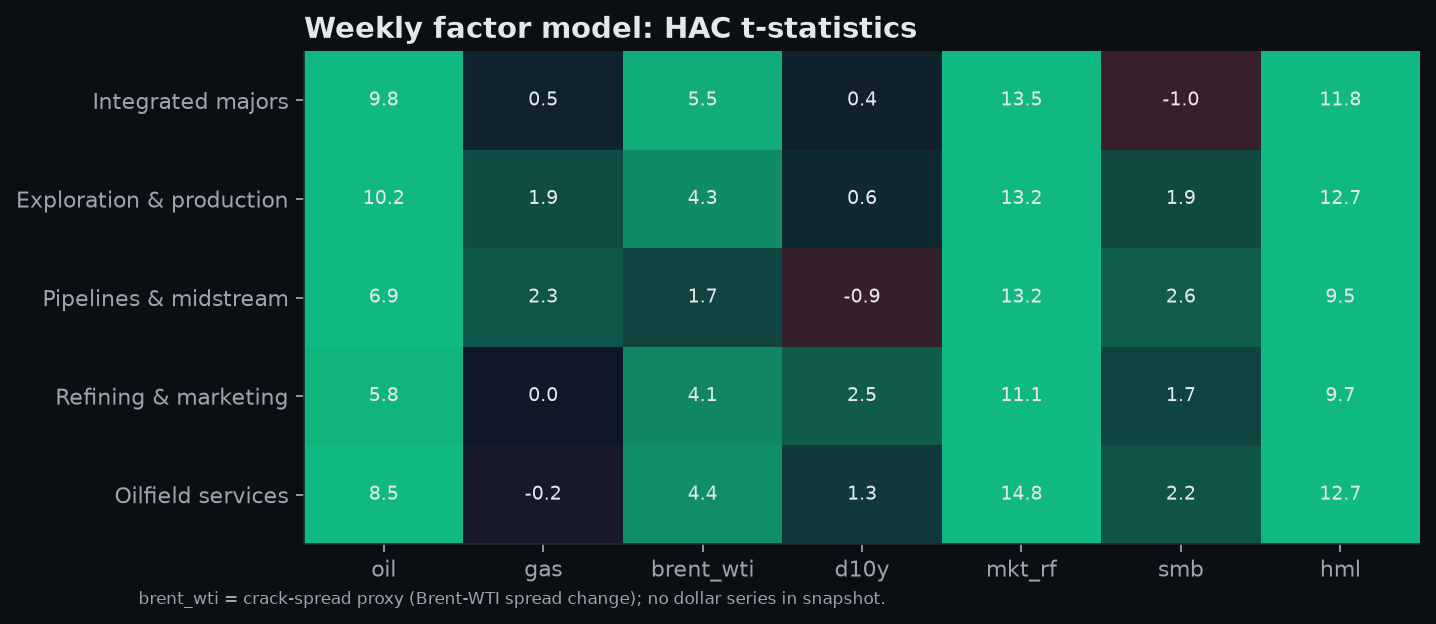

In [5]:
Image('../docs/img/factor_tstats.png')

In [6]:
pd.DataFrame({'explanatory (same-week factors)': {s: v['vs_hist_mean'] for s, v in res['walk_forward_explanatory'].items()},
              'predictive (lag-1 factors)': {s: v['vs_hist_mean'] for s, v in res['walk_forward_predictive_lag1'].items()},
              'predictive vs zero': {s: v['vs_zero'] for s, v in res['walk_forward_predictive_lag1'].items()}})

,explanatory (same-week factors),predictive (lag-1 factors),predictive vs zero
majors,0.676,-0.060,-0.059
upstream,0.668,-0.056,-0.057
midstream,0.533,-0.077,-0.075
refiners,0.571,-0.037,-0.032
services,0.642,-0.058,-0.060


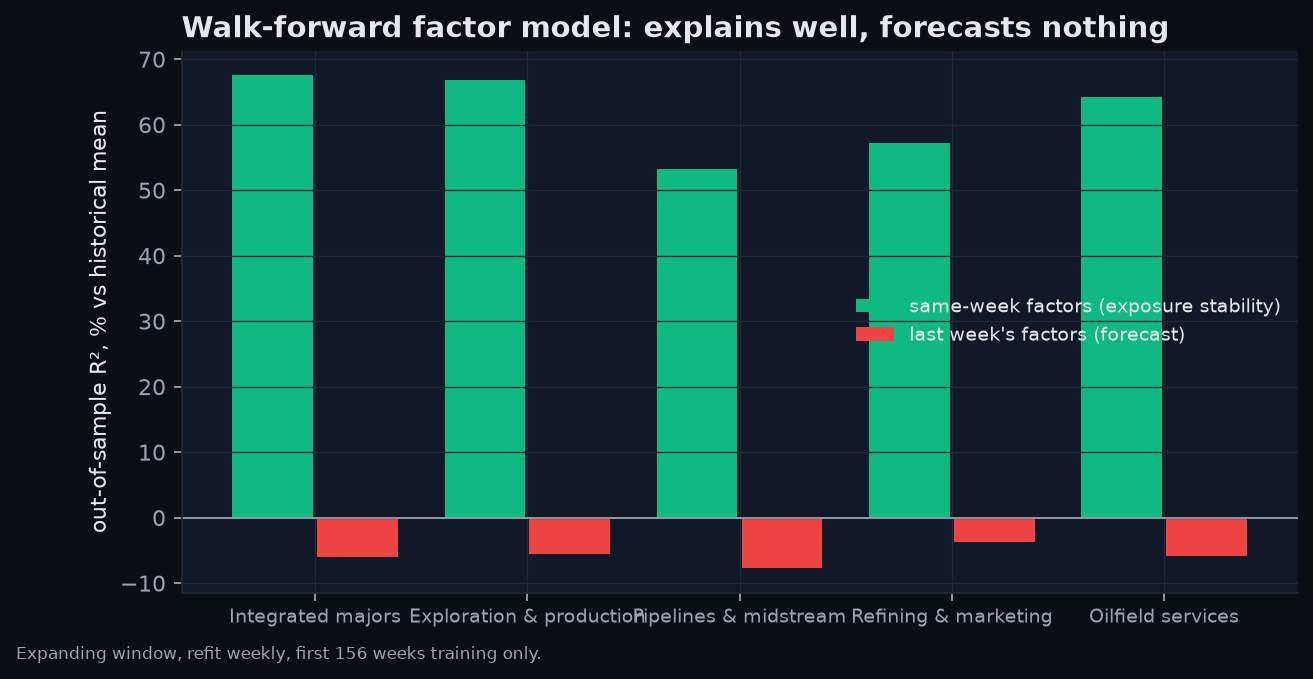

In [7]:
Image('../docs/img/oos_r2.png')

**Takeaway.** The exposures are real and stable: same-week factors explain more than half of weekly variance out of sample. Last week's factors forecast nothing, with out-of-sample R² below zero against both baselines. That is what an efficient market predicts, and it is why the scenario tool is framed as sensitivity analysis.